# Chapter 5 (part 3) — Evaluating Classifiers: Who Should the Retention Budget Target?

Covers: Evaluating Classification Models (confusion matrix, the rare-class problem, precision/recall/specificity, ROC, AUC, lift) → Strategies for Imbalanced Data (up-weighting, cost-based classification), on **churn**.

This notebook answers the Chapter 5 project question: **who should a limited retention budget target?** Notebook 14 left you with a calibrated logistic model at 0.801 accuracy. But "accuracy at a 0.5 cutoff" was always a placeholder: churners are only 26.5% of customers, the retention team doesn't care about stayers labeled correctly, and nobody said 0.5 was the right cutoff. Here you replace it with the measures used in practice.

Same fixed split. Your notebook-14 model (base spec + six add-on flags, AIC 4147.5) and notebook 13's baselines are rebuilt in setup. Your `log_tenure` and add-on flags now live in `mlstats.features.add_logit_features`. There's no feature step this time, because the inputs don't change; the work is all in how you score the model.

**How to work each section:** write your prediction **before** running anything, do the code, then 2-3 bullets on what matched and what didn't. The exam is appended to `reviews/R02_classification.ipynb` (Q6–Q8; ★Q6 is the one to do).

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.naive_bayes import CategoricalNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

pd.set_option("display.max_columns", None)

from mlstats.data import load_churn_split
from mlstats.features import ADDONS, add_churn_features, add_logit_features

train, test = load_churn_split()
train_f = add_logit_features(add_churn_features(train))   # your notebook-13 + notebook-14 features
test_f = add_logit_features(add_churn_features(test))
y_train, y_test = train_f["churned"].to_numpy(), test_f["churned"].to_numpy()

# your notebook-14 model, rebuilt
BASE = 'churned ~ tenure + MonthlyCharges + C(Contract, Treatment("Two year")) + InternetService + PaymentMethod + PaperlessBilling + SeniorCitizen'
FORMULA = BASE + " + " + " + ".join(c + "_yes" for c in ADDONS)
logit_fixed = smf.logit(FORMULA, data=train_f).fit(disp=0)
p_logit = logit_fixed.predict(test_f).to_numpy()

# notebook 13's baselines, rebuilt
lean_cols = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling", "SeniorCitizen", "tenure_band", "addon_count"]
enc = OrdinalEncoder().fit(train_f[lean_cols].astype(str))
p_nb_lean = (CategoricalNB().fit(enc.transform(train_f[lean_cols].astype(str)), y_train)
             .predict_proba(enc.transform(test_f[lean_cols].astype(str)))[:, 1])
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "addon_count", "charge_drift"]
scaler = StandardScaler().fit(train_f[num_cols])
p_lda = (LinearDiscriminantAnalysis().fit(scaler.transform(train_f[num_cols]), y_train)
         .predict_proba(scaler.transform(test_f[num_cols]))[:, 1])

print(f"AIC {logit_fixed.aic:.1f} | test: {len(y_test)} customers, {y_test.sum()} churners ({y_test.mean():.1%})")

AIC 4147.5 | test: 2113 customers, 561 churners (26.5%)


## 1. The Confusion Matrix and the Rare-Class Problem

Covers: *Confusion Matrix*, *The Rare Class Problem*, *Precision, Recall, and Specificity* (book). Pick a cutoff, flag everyone above it, and count four boxes. Numeric picture with 100 customers, 27 of whom churn: the model flags 20, and 13 of those really churn.

| | actually churn | actually stay |
|---|---|---|
| **flagged** | TP = 13 | FP = 7 |
| **not flagged** | FN = 14 | TN = 66 |

- **Precision** = 13 / 20 = **65%**: of the people you'd call, how many were really leaving.
- **Recall** (sensitivity) = 13 / 27 = **48%**: of the people leaving, how many you'd reach.
- **Specificity** = 66 / 73 = **90%**: of the stayers, how many you correctly left alone.
- Accuracy = 79 / 100. "Everyone stays" scores 73 / 100 with **zero** recall. That's the rare-class problem: when one class dominates, accuracy rewards ignoring the class you care about.

Write one function and call it at two cutoffs, 0.5 and 0.3.

**Predict first:** moving the cutoff from 0.5 down to 0.3, does recall rise by under 10 points, 10–30 points, or more than 30? And does precision fall below 50%?

*Tools for this question:*
- `pred = p >= cutoff`; `tp = np.sum(pred & (y == 1))`, and likewise for the other three boxes.
- `confusion_matrix(y, pred).ravel()` returns **(tn, fp, fn, tp)** in that order, with TN first (gotcha). Use it to check your by-hand counts, not instead of them.

_Prediction (one line, before running anything):_
* recall is the models ability to correctly identify consumers who churn. If we decrease the threshold, then the minimum bar for "churn" consumers will be lower and more will be identified as such label. I believe recall will rise under 10 points since many non-churn consumers are now available to the model to be selected as churn.
* Precision is the model's metric that tells us of how all the churn consumers it predicted, how many actually churned. Reducing the threshold will allow the model to select more consumers it identifies as churn and therefor misclassify more consumers. So I believe precision will fall below 50%.

In [5]:
def confusion_at(p, y, cutoff):
    """Return a dict with tp, fp, fn, tn, precision, recall, specificity, accuracy at this cutoff."""
    pred = p >= cutoff

    tp = np.sum(pred & (y == 1))
    fp = np.sum(pred & (y == 0))
    tn = np.sum((~pred) & (y == 0))
    fn = np.sum((~pred) & (y == 1))

    precision = tp/(tp + fp)
    recall = tp/(tp+fn)
    specificity = tn/(tn + fp)

    confusion_dict = {"tp" : tp,
                      "fp" : fp,
                      "tn" : tn,
                      "fn" : fn,
                      "precision" : precision,
                      "recall" : recall,
                      "specificity" : specificity}

    return confusion_dict

In [6]:
# pre-filled: consumes your confusion_at
pd.DataFrame({c: confusion_at(p_logit, y_test, c) for c in (0.5, 0.3)}).T.round(3)

,tp,fp,tn,fn,precision,recall,specificity
0.5,301.0,161.0,1391.0,260.0,0.652,0.537,0.896
0.3,433.0,374.0,1178.0,128.0,0.537,0.772,0.759


_What matched, what surprised you, and why (2-3 bullets):_
* Recall rose from 0.537 to 0.772 (about +24 points), so my "under 10" was wrong, and so was my reasoning: recall only counts churners, so non-churners being available can't move it. It rose because the model flags 132 more actual churners (TP 301 → 433); many churners score between 0.3 and 0.5.
* Precision fell from 0.652 to 0.537 but stayed above 50%, so that prediction was wrong too. False positives rose about 2.3x (161 → 374) while true positives only rose 1.4x.
* The 345 extra customers flagged in the 0.3–0.5 band are only 38% churners (132 / 345). That is well above the 26.5% base rate, which is why recall jumped, and below the 65% precision at 0.5, which is why precision dropped. Lowering the cutoff trades precision (and specificity, 0.896 → 0.759) for recall.

## 2. ROC and AUC: Scoring the Ranking, Not One Cutoff

Covers: *ROC Curve*, *AUC* (book). Section 1's numbers depend on the cutoff. The **ROC curve** shows every cutoff at once: recall (true positive rate) against 1 − specificity (false positive rate) as the cutoff sweeps from 1 down to 0. The **AUC** has a plain meaning: the probability that a randomly chosen churner gets a higher score than a randomly chosen stayer. Numeric picture: churners scored 0.8, 0.6 and 0.3; stayers scored 0.5 and 0.2. Of the 3 × 2 = 6 churner-stayer pairs, the churner is higher in 5 (only 0.3 vs. 0.5 loses), so AUC = 5/6 = **0.83**. A coin flip gives 0.5; a perfect ranking gives 1.0. AUC only cares about order, so any change that keeps the order leaves it unchanged.

(a) **By hand, once:** compute logistic's AUC as the share of (churner, stayer) pairs where the churner scores higher, counting ties as half.
(b) **Library:** `roc_auc_score` for all three models.

**Predict first:** (a) will the three models rank the same by AUC as they did by accuracy (logistic 0.801 > LDA 0.793 > Naive Bayes 0.762)? (b) Will Naive Bayes's AUC come within 0.03 of logistic's, even though its probabilities were badly off?

*Tools for this question:*
- `pos, neg = p[y == 1], p[y == 0]`, then `(pos[:, None] > neg[None, :]).mean()` compares every pair at once (broadcasting: a 561 × 1,552 grid of True/False). Add `0.5 * (pos[:, None] == neg[None, :]).mean()` for ties.
- `roc_auc_score(y_true, scores)` → AUC.

_Prediction (one line, before running anything):_
* I dont think the models will rank the same as accuracy.
* I believe that naive bayes may have strength in ranking which is kind of what AUC shows in a way. So I will say that it comes within 0.03 of logistics.

In [11]:
pos, neg = p_logit[y_test == 1], p_logit[y_test == 0]

auc_pairs = (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()  # by hand: share of (churner, stayer) pairs where the churner's p_logit is higher (ties = 0.5)
aucs = {"Logistic" : roc_auc_score(y_test, p_logit),
        "Naive Bayes, lean" : roc_auc_score(y_test, p_nb_lean),
        "LDA" : roc_auc_score(y_test, p_lda),
     }     # dict: {"Logistic": ..., "LDA": ..., "Naive Bayes, lean": ...} from roc_auc_score

by hand: 0.8428 | roc_auc_score: 0.8428

                     AUC  accuracy@0.5
Logistic           0.843         0.801
Naive Bayes, lean  0.823         0.762
LDA                0.817         0.793 



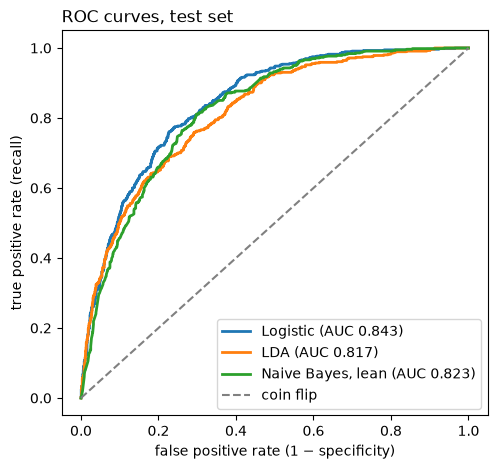

In [12]:
# pre-filled: consumes auc_pairs, aucs
print(f"by hand: {auc_pairs:.4f} | roc_auc_score: {aucs['Logistic']:.4f}\n")
acc = {"Logistic": p_logit, "LDA": p_lda, "Naive Bayes, lean": p_nb_lean}
print(pd.DataFrame({"AUC": aucs, "accuracy@0.5": {k: np.mean((v >= 0.5) == y_test) for k, v in acc.items()}}).round(3), "\n")

fig, ax = plt.subplots(figsize=(5.5, 5))
for name, p in acc.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC {aucs[name]:.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="coin flip")
ax.set_xlabel("false positive rate (1 − specificity)"); ax.set_ylabel("true positive rate (recall)")
ax.legend(loc="lower right"); ax.set_title("ROC curves, test set", loc="left"); plt.show()

_What matched, what surprised you, and why (2-3 bullets):_
* Naive Bayes had the worst accuracy (0.762) but its AUC (0.823) came in only 0.020 below logistic (0.843), so the within-0.03 prediction matched.
* The models did not rank the same way as in accuracy: by accuracy it was logistic > LDA > Naive Bayes, but by AUC Naive Bayes (0.823) and LDA (0.817) swap places.
* Why: AUC only uses the order of the scores, while accuracy@0.5 also depends on the probabilities being well calibrated at the 0.5 cutoff. Naive Bayes ranks customers well even though its raw probabilities are off, so it loses on accuracy but not on AUC.

## 3. Lift: Who to Call When You Can't Call Everyone

Covers: *Lift* (book). A retention team with a fixed budget doesn't pick a cutoff; it picks how many customers it can afford to contact, and contacts the highest-scored ones. **Lift** says how much better that list is than calling at random. Numeric picture: the overall churn rate is 26.5%. If the top 10% of customers by score churn at 66%, lift = 66 / 26.5 = **2.5**: each call reaches 2.5 times as many churners as a random call. The **cumulative gains** view asks the same thing from the other side: contacting the top 20%, what share of *all* churners do you reach?

Write one function and call it for the top 10%, 20% and 30% by `p_logit`.

**Predict first:** (a) is the top-10% lift under 2×, between 2× and 3×, or over 3×? (b) Calling the top 20% reaches about what share of all churners: ~20%, ~35%, or ~50%?

*Tools for this question:*
- `order = np.argsort(-p)` sorts customers from highest to lowest score; `y[order][:k]` are the outcomes of the top k.
- `k = int(round(frac * len(y)))`.

_Prediction (one line, before running anything):_
* I predict the highest churners are between 2x and 3x
* If the cutoff is 50%, then the top 20% of top scorers would most likely be about 50% of churners.

In [13]:
def lift_at(p, y, frac):
    """Return a dict: churn_rate in the top frac by score, lift vs. the overall churn rate, share_of_churners captured."""
    # sort predicted scores
    order = np.argsort(-p)

    # get top k amount and outcomes
    k =int(round(len(order) * frac))
    outcomes = y[order][:k]

    result_dict = {
        "churn rate" : outcomes.mean(),
        "lift vs. overall churn" : outcomes.mean()/y.mean(),
        "share of churners captured" : np.sum(outcomes)/np.sum(y[order])
    }

    return result_dict

         churn rate  lift vs. overall churn  share of churners captured
top 10%       0.735                   2.767                       0.276
top 20%       0.657                   2.475                       0.496
top 30%       0.580                   2.186                       0.656 



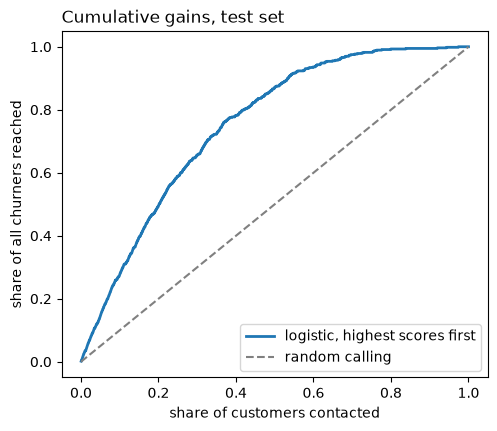

In [14]:
# pre-filled: consumes your lift_at, then the cumulative gains chart
print(pd.DataFrame({f"top {int(f * 100)}%": lift_at(p_logit, y_test, f) for f in (0.1, 0.2, 0.3)}).T.round(3), "\n")

order = np.argsort(-p_logit)
gains = np.cumsum(y_test[order]) / y_test.sum()
share = np.arange(1, len(y_test) + 1) / len(y_test)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot(share, gains, lw=2, label="logistic, highest scores first")
ax.plot([0, 1], [0, 1], "--", color="gray", label="random calling")
ax.set_xlabel("share of customers contacted"); ax.set_ylabel("share of all churners reached")
ax.legend(loc="lower right"); ax.set_title("Cumulative gains, test set", loc="left"); plt.show()

_What matched, what surprised you, and why (2-3 bullets):_
* My prediction was correct. The top 10% by score churn at 73.5%, a lift of 2.77, so calling them reaches 2.77 times as many churners as a random call.
* My prediction about the top 20% was also correct: it reaches 49.6% of all churners, where random calling would reach 20%. My reasoning was off, though: the gains view has no cutoff in it, you contact the top k by rank. The "50% cutoff" idea belongs to section 1.
* Lift falls as I contact more people (2.77 → 2.48 → 2.19 for the top 10%, 20%, 30%), because the extra customers have lower scores and so are less likely to churn.

## 4. Imbalanced Data and the Cost-Based Cutoff

Covers: *Strategies for Imbalanced Data* → *Oversampling and Up/Down Weighting*, *Cost-Based Classification* (book; undersampling and SMOTE are exam-only here). Two different fixes for "churners are rare":

- **Up-weighting** counts each churner more in the fit. Weighting churners by 3,622 / 1,308 ≈ 2.77 makes the two classes weigh the same.
- **Cost-based classification** leaves the model alone and picks the cutoff from what decisions cost. Numeric picture, with assumptions you'd get from the business: a retention offer costs **$60**, a saved churner is worth **$600**, and **30%** of churners who get the offer stay. Contacting a customer with churn probability p is worth, on average, p × 0.30 × $600 − $60 = 180·p − 60 dollars. That's positive when p > 60/180 = **1/3**, so the cutoff comes from the costs, not from 0.5.

*Supplementary (Causal):* that formula assumes the offer works equally on every churner and does nothing for stayers. Phase 4's uplift models question exactly that assumption.

(a) Refit `FORMULA` with churners up-weighted → `p_weighted`.
(b) **The heavy step:** for cutoffs 0.05, 0.10, …, 0.95, compute the realized test-set profit of contacting everyone at or above the cutoff with `p_logit`: (churners contacted) × 0.30 × $600 − (customers contacted) × $60.

**Predict first:** (a) after up-weighting, does AUC rise by more than 0.01, stay within 0.01, or fall? Does the mean predicted probability stay near the actual 26.5%? (b) Is the most profitable cutoff closer to 0.5 or to 1/3?

*Tools for this question:*
- `w = np.where(y_train == 1, (y_train == 0).sum() / (y_train == 1).sum(), 1.0)`.
- `smf.glm(FORMULA, data=train_f, family=sm.families.Binomial(), freq_weights=w).fit()`; `.predict(test_f)` → probabilities. (`smf.logit` has no weights argument; the binomial GLM is the same model.)
- Loop over `np.round(np.arange(0.05, 0.951, 0.05), 2)`. The rounding avoids keys like 0.30000000000000004.

_Prediction (one line, before running anything):_
* I believe adding more weight to churners will cause AUC to stay the same.
* I believe the mean predicted probability will deviate from the actual 26.5%.
* I think the profitable cutoff will be 1/3. 


In [17]:
w = np.where(y_train == 1, (y_train == 0).sum() / (y_train == 1).sum(), 1.0)
weighted_model = smf.glm(FORMULA, data=train_f, family=sm.families.Binomial(), freq_weights=w).fit()   # P(churn) on test_f from FORMULA refit with churners up-weighted
p_weighted = weighted_model.predict(test_f)

In [18]:
# pre-filled: consumes p_weighted
print(f"mean predicted P: unweighted {p_logit.mean():.3f} | weighted {p_weighted.mean():.3f} | actual {y_test.mean():.3f}")
print(f"AUC: unweighted {roc_auc_score(y_test, p_logit):.4f} | weighted {roc_auc_score(y_test, p_weighted):.4f}")
print(f"rank correlation (Spearman) between the two scores: {pd.Series(p_logit).corr(pd.Series(p_weighted), method='spearman'):.4f}")
for name, p in (("unweighted @0.5", p_logit), ("weighted @0.5", p_weighted)):
    pred = p >= 0.5
    print(f"{name:16s} flagged {pred.sum():4d} | recall {pred[y_test == 1].mean():.3f} | precision {y_test[pred].mean():.3f}")

mean predicted P: unweighted 0.267 | weighted 0.418 | actual 0.265
AUC: unweighted 0.8428 | weighted 0.8425
rank correlation (Spearman) between the two scores: -0.0097
unweighted @0.5  flagged  462 | recall 0.537 | precision 0.652
weighted @0.5    flagged  878 | recall 0.795 | precision 0.508


In [23]:
profit = {} # pd.Series indexed by cutoff (0.05 ... 0.95): realized test-set profit from contacting p_logit >= cutoff

for cutoff in np.round(np.arange(0.05, 0.951, 0.05), 2):
    reach_out = y_test[p_logit >= cutoff]
    churners = np.sum(reach_out)
    total_contacted = len(reach_out)

    realized_profit = (churners * .3 * 600) - total_contacted * 60
    profit[cutoff] = realized_profit

profit = pd.Series(profit)

break-even probability from the costs: 0.333
best cutoff 0.3 → $29,520 (contacting 807 customers) | cutoff 0.5 → $26,460
contact everyone → $-25,800


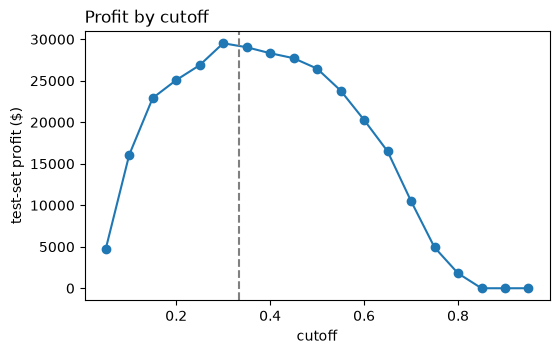

In [24]:
# pre-filled: consumes profit
best = profit.idxmax()
print(f"break-even probability from the costs: {60 / (0.30 * 600):.3f}")
print(f"best cutoff {best} → ${profit[best]:,.0f} (contacting {np.sum(p_logit >= best)} customers) | cutoff 0.5 → ${profit[0.5]:,.0f}")
print(f"contact everyone → ${y_test.sum() * 0.30 * 600 - len(y_test) * 60:,.0f}")
ax = profit.plot(marker="o", figsize=(6, 3.5)); ax.axvline(1 / 3, ls="--", color="gray")
ax.set_xlabel("cutoff"); ax.set_ylabel("test-set profit ($)"); ax.set_title("Profit by cutoff", loc="left"); plt.show()

_What matched, what surprised you, and why (2-3 bullets):_
* Adding weight to the churner class kept AUC the same (0.8428 vs. 0.8425). Up-weighting shifts every score up but barely changes how customers are ordered, and AUC only reads the order.
* The weighted model's mean predicted probability was 41.8%, much higher than the actual 26.5%. The weighted fit treats churners as half the data, so the probabilities inflate: same ranking, wrong scale. At 0.5 it flags 878 customers (recall 0.795, precision 0.508) versus 462 for the unweighted model, so up-weighting acts like lowering the cutoff, and the 1/3 rule wouldn't apply to its scores.
* 1/3 was correct: the best cutoff was 0.30, the grid point closest to 1/3, at $29,520 versus $26,460 at 0.5. The 1/3 comes from the costs, 60 / 180.

**Chapter 5's answer to the project question:** in two or three sentences, who should a limited retention budget target, and how would you choose how many to contact? Say which model, which measure, and one assumption you'd want the business to confirm.

* Aim the budget at the highest-scored customers, since lift is highest there (2.77x in the top 10%), and stop where a customer's churn probability falls below the cost-based break-even of 1/3 (60 / 180).
* How many: everyone above 1/3, which is about 800 customers (807, or 38% of the test set, at cutoff 0.30). If the budget is smaller than that, take the top k by score. The cutoff, not the top 10%, says where contacting stops paying off.
* Model and measure: the unweighted logistic regression (best accuracy 0.801 and AUC 0.843, with calibrated probabilities), judged by expected profit, not accuracy or AUC. My main assumption to confirm is that the offer is equally effective on all churners (30%) and does nothing for stayers, which is most likely not the case.